# TWFE + DML on synthetic panel data, with Optuna tuning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/firefly1248/demo-notebooks/blob/main/notebooks/causal/twfe_dml_demo_with_tuning.ipynb)

Compares naive OLS, TWFE and TWFE + DML (random forest nuisance models) on a synthetic panel with an unobserved entity confounder and quadratic observed confounders, then tunes the nuisance models with Optuna under two DML-aware criteria (R-loss and score variance). True effect: $\theta = 1$.

In [ ]:
from importlib.metadata import version, PackageNotFoundError

def installed(package, pin):
    try:
        return version(package) == pin
    except PackageNotFoundError:
        return False

if not all(installed(p, v) for p, v in (("optuna", "4.8.0"), ("statsmodels", "0.14.6"))):
    !pip install -q optuna==4.8.0 statsmodels==0.14.6

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import optuna
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, cross_val_predict

optuna.logging.set_verbosity(optuna.logging.WARNING)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

## 1. Data-generating process

Unobserved entity confounder $u_i \sim \mathcal{N}(0, 1.5^2)$; observed covariates $x_1, x_2, x_3 \sim \mathcal{N}(0, 1)$.

$e(x) = 0.6 x_1^2 + 0.4 x_2^2 - 1$, $\quad g(x) = 1.2 x_1^2 + 0.8 x_2^2 + 0.5 x_3^2 - 2.5$

Treatment: $T_{it} = 1.2\, u_i + e(x_{it}) + \mathrm{season}^T_t + \varepsilon^T_{it}$, with $\mathrm{season}^T_t = 0.3 \sin(2\pi t/12 + 1)$ and $\varepsilon^T \sim \mathcal{N}(0, 0.6^2)$.

Outcome: $Y_{it} = \theta\, T_{it} + 1.5\, u_i + g(x_{it}) + \mathrm{trend}_t + \mathrm{season}^Y_t + \varepsilon^Y_{it}$, with $\mathrm{trend}_t = 0.04 t$, $\mathrm{season}^Y_t = 0.5 \sin(2\pi t/12)$ and $\varepsilon^Y \sim \mathcal{N}(0, 1)$.

`e(x)` and `g(x)` share `x_1^2, x_2^2`, so `x` confounds T and Y only through squares: linear controls in `x` miss it, with or without TWFE.

In [2]:
N_ENTITIES, N_PERIODS, SEED = 20_000, 12, 2026
THETA_TRUE = 1.0

rng = np.random.default_rng(SEED)
N = N_ENTITIES * N_PERIODS

entity_idx = np.repeat(np.arange(N_ENTITIES), N_PERIODS)
time_idx   = np.tile(np.arange(N_PERIODS), N_ENTITIES)

u_i = rng.normal(0, 1.5, N_ENTITIES)
trend    = 0.04 * time_idx
season_y = 0.5 * np.sin(2 * np.pi * time_idx / N_PERIODS)
season_t = 0.3 * np.sin(2 * np.pi * time_idx / N_PERIODS + 1.0)

x_1, x_2, x_3 = rng.normal(0, 1, (3, N))

e_x = 0.6 * x_1**2 + 0.4 * x_2**2 - 1.0
t = 1.2 * u_i[entity_idx] + e_x + season_t + rng.normal(0, 0.6, N)
g_x = 1.2 * x_1**2 + 0.8 * x_2**2 + 0.5 * x_3**2 - 2.5
y = (THETA_TRUE * t + 1.5 * u_i[entity_idx] + g_x
     + trend + season_y + rng.normal(0, 1.0, N))

df = pd.DataFrame({
    'id': entity_idx, 'time': time_idx,
    'x_1': x_1, 'x_2': x_2, 'x_3': x_3,
    't': t, 'y': y,
})

print(f"Shape: {df.shape}   True theta: {THETA_TRUE}")
print(f"u_i is NOT in df (unobserved). corr(T, u_i) = {np.corrcoef(t, u_i[entity_idx])[0,1]:.3f}")
df.head()

Shape: (240000, 7)   True theta: 1.0
u_i is NOT in df (unobserved). corr(T, u_i) = 0.833


,id,time,x_1,x_2,x_3,t,y
0,0,0,0.768580,0.741789,-0.731810,-1.556717,-3.611105
1,0,1,-0.948917,0.415008,0.565348,-1.474106,-5.295372
2,0,2,-0.253207,-0.184073,0.429508,-1.886370,-5.783631
3,0,3,1.285489,-0.806929,-1.116279,-0.601954,-3.815775
4,0,4,0.669900,-1.978702,-0.716705,-1.273578,-1.818325


## 2. EDA: entity means reveal `u_i`

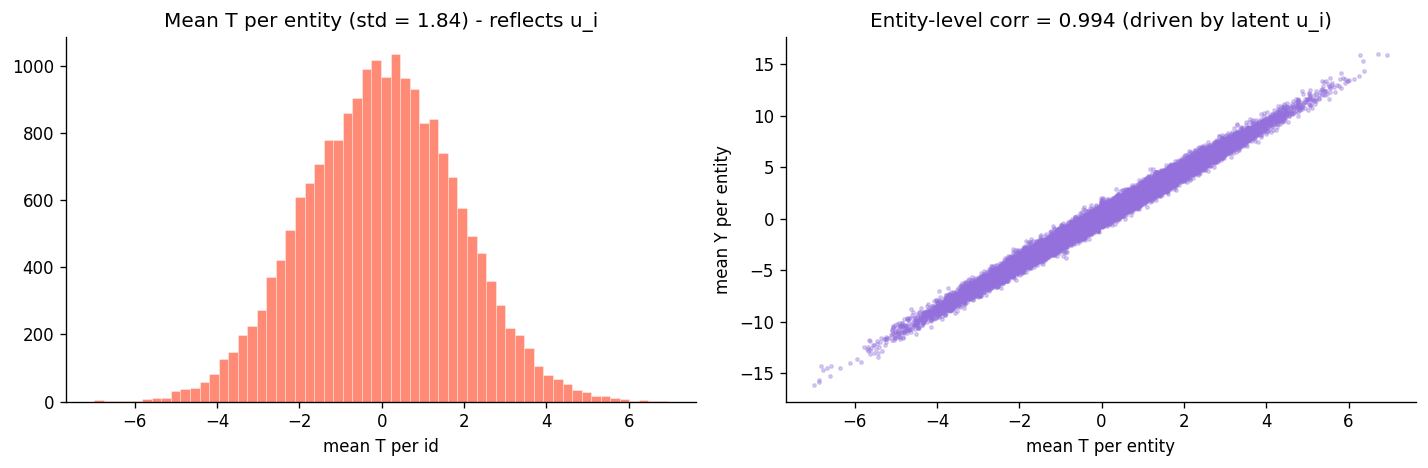

In [3]:
ent = df.groupby('id')[['t', 'y']].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(ent['t'], bins=60, color='tomato', alpha=0.75, edgecolor='white', linewidth=0.3)
axes[0].set_title(f"Mean T per entity (std = {ent['t'].std():.2f}) - reflects u_i")
axes[0].set_xlabel('mean T per id')

axes[1].scatter(ent['t'], ent['y'], s=4, alpha=0.3, color='mediumpurple')
axes[1].set_xlabel('mean T per entity')
axes[1].set_ylabel('mean Y per entity')
axes[1].set_title(f"Entity-level corr = {ent['t'].corr(ent['y']):.3f} (driven by latent u_i)")
plt.tight_layout(); plt.show()

## 3. Naive OLS - cannot see `u_i`

Omits `u_i` (which raises both T and Y) and controls for `x` only linearly, so the bias is upward.

In [4]:
groups = df['id'].values
rows = []

def ols_theta(y, X):
    # coefficient on the first regressor, 95% CI clustered by entity
    fit = sm.OLS(y, sm.add_constant(X)).fit(cov_type='cluster', cov_kwds={'groups': groups})
    return fit.params[1], *fit.conf_int()[1]

def record(label, est, lo, hi):
    rows.append((label, est, lo, hi))
    print(f"{label:>30}  theta = {est:.4f}  CI=[{lo:.3f}, {hi:.3f}]  bias = {est - THETA_TRUE:+.4f}")

record('Naive OLS (no panel)', *ols_theta(df['y'].values, df[['t', 'x_1', 'x_2', 'x_3']].values))

          Naive OLS (no panel)  theta = 2.3112  CI=[2.308, 2.315]  bias = +1.3112


## 4. TWFE - entity demeaning purges `u_i`

Since `u_i` is constant per entity, subtracting entity means removes it from T and Y (we also subtract time means and add back the grand mean). The latent confounder is gone without ever being observed.

**But:** linear controls cannot capture the quadratic `e(x)` and `g(x)`, so the x^2 confounding remains. TWFE is even worse than naive OLS: demeaning removes the `u_i` share of Var(T), while the x^2 bias term is unchanged and is now divided by a smaller variance.

In [5]:
# Square before demeaning: TWFE needs (x^2)_dm, not (x_dm)^2.
for j in (1, 2, 3):
    df[f'x_{j}_sq'] = df[f'x_{j}'] ** 2

cols = ['t', 'y', 'x_1', 'x_2', 'x_3', 'x_1_sq', 'x_2_sq', 'x_3_sq']
dm = (df[cols] - df.groupby('id')[cols].transform('mean')
      - df.groupby('time')[cols].transform('mean') + df[cols].mean())
df[[f'{c}_dm' for c in cols]] = dm.to_numpy()

record('TWFE only (linear x_dm)',
       *ols_theta(df['y_dm'].values, df[['t_dm', 'x_1_dm', 'x_2_dm', 'x_3_dm']].values))

       TWFE only (linear x_dm)  theta = 2.4855  CI=[2.479, 2.493]  bias = +1.4855


## 5. TWFE + DML - partialling out nonlinear `g(x)` with a random forest

Cross-fitting uses `GroupKFold` on `id`, so an entity is never in both train and test of a fold.

**(a) Raw `x_dm` features.** The entity mean of `g(x)` depends on the entity's other periods, so `g(x)_dm` is not a function of `x_dm` alone; the RF only partially recovers it.

**(b) Engineered `x_sq_dm` features.** Square `x_j` before demeaning, then demean. Since `e` and `g` are sums of `x_j^2`, `e(x)_dm` and `g(x)_dm` are linear in `x_sq_dm`. On real data the basis is unknown, so this helps only as far as the engineered features span `e` and `g`.

In [6]:
cv = GroupKFold(n_splits=5)
t_arr, y_arr = df['t_dm'].values, df['y_dm'].values
RF_PARAMS = dict(n_estimators=300, min_samples_leaf=10, max_features=1.0)  # hand-picked; tuned in section 6

def oof_residuals(X, params):
    # cross-fitted residuals (y_res, t_res)
    rf = RandomForestRegressor(random_state=42, n_jobs=-1, **params)
    return (y_arr - cross_val_predict(rf, X, y_arr, cv=cv, groups=groups),
            t_arr - cross_val_predict(rf, X, t_arr, cv=cv, groups=groups))

X_raw = df[['x_1_dm', 'x_2_dm', 'x_3_dm']].values
X_eng = df[['x_1_dm', 'x_2_dm', 'x_3_dm', 'x_1_sq_dm', 'x_2_sq_dm', 'x_3_sq_dm']].values

# final stage: OLS of y residuals on t residuals
record('TWFE + DML (raw x_dm)', *ols_theta(*oof_residuals(X_raw, RF_PARAMS)))
record('TWFE + DML (x_dm + x_sq_dm)', *ols_theta(*oof_residuals(X_eng, RF_PARAMS)))

         TWFE + DML (raw x_dm)  theta = 1.8182  CI=[1.809, 1.827]  bias = +0.8182


   TWFE + DML (x_dm + x_sq_dm)  theta = 1.0018  CI=[0.995, 1.009]  bias = +0.0018


## 6. Optuna tuning - R-loss vs score variance

Tuning the RF hyperparameters on the engineered features with two DML-aware criteria computed on out-of-fold residuals:

- **R-loss** (Nie & Wager 2021):  $L_R = \frac{1}{n}\sum_i \big[(y_i - \hat m(x_i)) - \hat\theta\,(t_i - \hat e(x_i))\big]^2$
- **Score variance:**  $\mathrm{Var}[\psi_i]$, $\psi_i = (t_i - \hat e(x_i))\{(y_i - \hat m(x_i)) - \hat\theta\,(t_i - \hat e(x_i))\}$, the variance of the orthogonal score (numerator of the sandwich variance of $\hat\theta$).

The t- and y-models share one hyperparameter set. Selection and the final estimate use the same residuals, so the tuned CI ignores the selection step.

In [7]:
N_TRIALS = 50
_cache = {}  # shared by both studies: repeated parameter sets are not refit

def cached_residuals(params):
    key = tuple(sorted(params.items()))
    if key not in _cache:
        _cache[key] = oof_residuals(X_eng, params)
    return _cache[key]

def objective(criterion):
    def _obj(trial):
        params = RF_PARAMS | {
            'max_depth':        trial.suggest_int('max_depth', 5, 25),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 50, log=True),
            'max_features':     trial.suggest_categorical('max_features', ['sqrt', 1.0]),
        }
        y_res, t_res = cached_residuals(params)
        theta = (y_res * t_res).sum() / (t_res ** 2).sum()  # no intercept: residuals are ~mean-zero
        trial.set_user_attr('theta_hat', theta)
        if criterion == 'R-loss':
            return ((y_res - theta * t_res) ** 2).mean()
        return (t_res * (y_res - theta * t_res)).var()
    return _obj

def progress(label):
    def cb(study, trial):
        print(f"  trial {trial.number+1:>2}/{N_TRIALS}: {label}={trial.value:>8.4f}  "
              f"theta={trial.user_attrs['theta_hat']:.4f}  best={study.best_value:.4f}")
    return cb

studies = {}
for name in ('R-loss', 'score-var'):
    print(f"=== Minimise {name} ===")
    studies[name] = optuna.create_study(sampler=optuna.samplers.TPESampler(seed=42))
    studies[name].optimize(objective(name), n_trials=N_TRIALS, callbacks=[progress(name)])
    print(f"Best params: {studies[name].best_params}\n")

for name, study in studies.items():
    record(f'TWFE + DML, {name}-tuned',
           *ols_theta(*cached_residuals(RF_PARAMS | study.best_params)))

=== Minimise R-loss ===


  trial  1/50: R-loss=  1.0003  theta=1.0734  best=1.0003


  trial  2/50: R-loss=  1.0456  theta=1.0171  best=1.0003


  trial  3/50: R-loss=  0.9537  theta=1.0045  best=0.9537


  trial  4/50: R-loss=  0.9728  theta=0.9995  best=0.9537


...

  trial 38/50: score-var=  0.3387  theta=1.0068  best=0.3189


  trial 39/50: score-var=  0.3836  theta=1.0268  best=0.3189
  trial 40/50: score-var=  0.3189  theta=1.0033  best=0.3189
  trial 41/50: score-var=  0.3176  theta=1.0030  best=0.3176
  trial 42/50: score-var=  0.3176  theta=1.0030  best=0.3176


  trial 43/50: score-var=  0.3188  theta=1.0025  best=0.3176
  trial 44/50: score-var=  0.3206  theta=1.0023  best=0.3176
  trial 45/50: score-var=  0.3188  theta=1.0025  best=0.3176
  trial 46/50: score-var=  0.3426  theta=1.0203  best=0.3176


  trial 47/50: score-var=  0.3250  theta=1.0018  best=0.3176
  trial 48/50: score-var=  0.3188  theta=1.0025  best=0.3176


  trial 49/50: score-var=  0.3316  theta=1.0011  best=0.3176
  trial 50/50: score-var=  0.3459  theta=1.0294  best=0.3176
Best params: {'max_depth': 12, 'min_samples_leaf': 1, 'max_features': 1.0}

      TWFE + DML, R-loss-tuned  theta = 1.0030  CI=[0.996, 1.010]  bias = +0.0030
   TWFE + DML, score-var-tuned  theta = 1.0030  CI=[0.996, 1.010]  bias = +0.0030


## 7. Comparison of estimators

                  estimator  theta_hat  ci_lo  ci_hi  bias  covers
       Naive OLS (no panel)      2.311  2.308  2.315 1.311   False
    TWFE only (linear x_dm)      2.486  2.479  2.493 1.486   False
      TWFE + DML (raw x_dm)      1.818  1.809  1.827 0.818   False
TWFE + DML (x_dm + x_sq_dm)      1.002  0.995  1.009 0.002    True
   TWFE + DML, R-loss-tuned      1.003  0.996  1.010 0.003    True
TWFE + DML, score-var-tuned      1.003  0.996  1.010 0.003    True


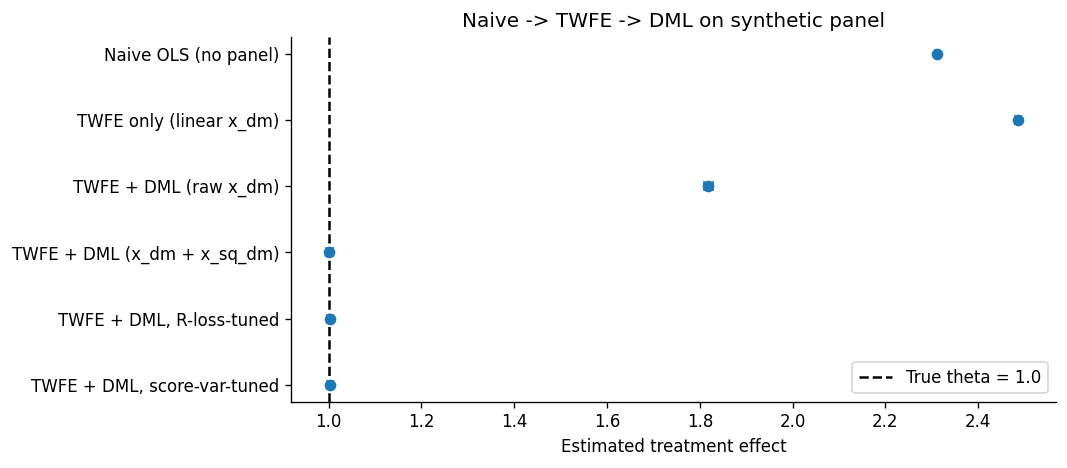

In [8]:
summary = pd.DataFrame(rows, columns=['estimator', 'theta_hat', 'ci_lo', 'ci_hi'])
summary['bias'] = summary['theta_hat'] - THETA_TRUE
summary['covers'] = (summary['ci_lo'] <= THETA_TRUE) & (THETA_TRUE <= summary['ci_hi'])
print(summary.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4))
pos = np.arange(len(summary))
ax.errorbar(summary['theta_hat'], pos, fmt='o', capsize=3,
            xerr=[summary['theta_hat'] - summary['ci_lo'], summary['ci_hi'] - summary['theta_hat']])
ax.axvline(THETA_TRUE, color='black', linestyle='--', label=f'True theta = {THETA_TRUE}')
ax.set_yticks(pos, summary['estimator'])
ax.invert_yaxis()
ax.set_xlabel('Estimated treatment effect')
ax.set_title('Naive -> TWFE -> DML on synthetic panel')
ax.legend(); plt.tight_layout(); plt.show()

## 8. Takeaways

1. **Naive OLS is badly biased.** It cannot see `u_i`, which enters T and Y with the same sign.
2. **TWFE with linear controls is even worse.** Demeaning removes `u_i` and its share of Var(T), but the x^2 confounding stays and is now divided by a smaller variance.
3. **DML on raw `x_dm` cuts the bias but still misses.** The RF only partially recovers the quadratic structure from demeaned features.
4. **Adding squares computed before demeaning recovers the truth** (CI covers 1.0): `(x^2)_dm != (x_dm)^2`, and `e(x)_dm`, `g(x)_dm` are linear in `x_sq_dm`.
5. **Optuna tuning agrees with the hand-picked setup.** R-loss and score variance select the same hyperparameters and give an estimate indistinguishable from the hand-picked one (CI covers 1.0).
6. **TWFE cannot fix** confounders varying within entity over time (`u_{it}`), entity-specific trends or reverse causality; these need IV, RDD or sensitivity analysis.